
# Exercises XP : Evaluating LLMs for Summarization



## What you will learn
- Hands-on evaluation for summarization: accuracy vs. ROUGE.
- Strengths/weaknesses of metrics and model size comparisons.
- Using Hugging Face `transformers` + `evaluate` for quick experiments.
- Data loading, sampling, preprocessing, and debugging model outputs.

**Create**: evaluation scripts, comparison tables, custom metrics, and short analyses.


In [1]:
# Part I. Setup (run once per runtime)
# Install minimal deps; keep quiet to reduce noise.
# !pip -q install rouge_score==0.1.2 evaluate datasets transformers accelerate nltk --quiet

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True


### Part II. Dataset loading and exploration
Preferred dataset: [abisee/cnn_dailymail](https://huggingface.co/datasets/abisee/cnn_dailymail) (map `article` -> `prompt_text`, `highlights` -> `prompt_title`).
- If you have local train/test CSVs with `prompt_text` / `prompt_title`, set the paths below.
- Otherwise, we will auto-sample a small slice from the HF dataset to keep things light.
- Show a couple of rows for a sanity check.
If HF download fails, a tiny fallback sample is used.


In [2]:
import pandas as pd
from datasets import load_dataset

# Point to your data; leave empty to use the HF cnn_dailymail sample or fallback
train_path = ''  # e.g., '/content/train.csv'
test_path = ''   # e.g., '/content/test.csv'

fallback = pd.DataFrame([
    {
        'prompt_text': 'The cat sat on the mat and purred loudly while the sun set.',
        'prompt_title': 'Cat rests on mat at sunset'
    },
    {
        'prompt_text': 'Scientists discovered water on the moon, opening new research paths.',
        'prompt_title': 'Water found on the moon'
    },
    {
        'prompt_text': 'The local team won the championship after a dramatic final match.',
        'prompt_title': 'Local team clinches title'
    },
])

def load_and_sample(path, split_name, n):
    if path:
        df = pd.read_csv(path)
    else:
        try:
            hf_split = f"{split_name}[:{max(n, 3)}]"
            ds = load_dataset('abisee/cnn_dailymail', '3.0.0', split=hf_split)
            df = ds.to_pandas()[['article', 'highlights']].rename(columns={'article': 'prompt_text', 'highlights': 'prompt_title'})
        except Exception as exc:
            print(f"HF load failed ({exc}); using tiny fallback sample.")
            df = fallback.copy()
    return df.sample(min(n, len(df)), random_state=42).reset_index(drop=True)

train_df = load_and_sample(train_path, 'train', 100)
test_df = load_and_sample(test_path, 'test', 50)

display(train_df.head(2))

README.md:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

3.0.0/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

3.0.0/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

...

3.0.0/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/287113 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/13368 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/11490 [00:00<?, ? examples/s]

,prompt_text,prompt_title
0,"SHANGHAI, China -- Championship leader Lewis H...",Lewis Hamilton fails to clinch world title aft...
1,(CNN) -- China has suspended exports of the Aq...,State-run news agency: China orders an investi...


In [3]:
print(f"Train sample: {train_df.shape}   Test sample: {test_df.shape}")
print(f"Columns: {list(train_df.columns)}\n")

first = train_df.iloc[0]
print("ARTICLE (prompt_text), first 800 characters:")
print(first["prompt_text"][:800], "...\n")
print("REFERENCE SUMMARY (prompt_title):")
print(first["prompt_title"])

Train sample: (100, 2)   Test sample: (50, 2)
Columns: ['prompt_text', 'prompt_title']

ARTICLE (prompt_text), first 800 characters:
SHANGHAI, China -- Championship leader Lewis Hamilton spun out of the Chinese Grand Prix to send the world title race to a cliffhanger finale in Brazil on October 21. A disconsolate Lewis Hamilton leaves his car after spinning into the gravel trap in Shanghai. Rookie Hamilton can still clinch the crown with third place in the closing race, but saw his 12-point lead cut to four by McLaren team-mate Fernando Alonso in Shanghai. The Spaniard finished second behind Ferrari's Kimi Raikkonen, who also kept his title hopes alive by moving within seven points of Hamilton. The young Briton started the race in pole position and at one stage led Raikkonen by more than eight seconds as he again showed superb skills in the wet conditions. However, the 22-year-old stayed out on the drying track too long ...

REFERENCE SUMMARY (prompt_title):
Lewis Hamilton fails to cli

In [4]:
# Lengths decide two settings later: how much of each article fits in a model's input
# window, and how many tokens a generated summary needs.
lengths = pd.DataFrame(
    {
        "article_words": train_df["prompt_text"].str.split().str.len(),
        "summary_words": train_df["prompt_title"].str.split().str.len(),
    }
)
display(lengths.describe().round(0))
print(f"Missing values:\n{train_df[['prompt_text', 'prompt_title']].isna().sum()}")
print(f"Duplicate articles: {train_df['prompt_text'].duplicated().sum()}")

display(train_df)
display(test_df)

,article_words,summary_words
count,100.0,100.0
mean,605.0,41.0
std,284.0,7.0
min,158.0,26.0
25%,355.0,37.0
50%,614.0,42.0
75%,778.0,46.0
max,1665.0,56.0


Missing values:
prompt_text     0
prompt_title    0
dtype: int64
Duplicate articles: 1


,prompt_text,prompt_title
0,"SHANGHAI, China -- Championship leader Lewis H...",Lewis Hamilton fails to clinch world title aft...
1,(CNN) -- China has suspended exports of the Aq...,State-run news agency: China orders an investi...
2,(CNN) -- The company was founded in 1985 by se...,The company has become a huge name in communic...
3,"ISLAMABAD, Pakistan (CNN) -- Hours after decla...",NEW: President Musharraf orders troops to take...
4,"QUEBEC, Canada -- Third seed Julia Vakulenko w...",Julia Vakulenko has reached her first final on...
...,...,...
95,"PARIS, France -- World number three Novak Djok...",World No. 3 Novak Djokovic beaten in the secon...
96,(CNN) -- A girl who was shown on a videotape b...,"Stiles described as ""survivalist type"" who car..."
97,"SAN FRANCISCO, California (CNN) -- A magnitud...","2,000 customers without electricity, power com..."
98,WASHINGTON (CNN) -- U.S. first lady Laura Bush...,"Laura Bush calls on Myanmar junta to ""step asi..."


,prompt_text,prompt_title
0,(CNN)A year ago Bloomberg published a story wi...,"LZ: Indiana law pushing back LGBT rights, and ..."
1,"(CNN)Mark Ronson's ""Uptown Funk!,"" featuring B...",The song rules the chart for 13th week .\nIt p...
2,"(CNN)Police in the Indian city of Malegaon, in...",Authorities in the Indian city of Malegaon hav...
3,"(CNN)""Jake the dog and Finn the human. The fun...",Thai Airways subsidiary Thai Smile features Ca...
4,"Marseille, France (CNN)The French prosecutor l...","Marseille prosecutor says ""so far no videos we..."
5,"(CNN)Universal's ""Furious 7"" continues to buil...","The final film featuring the late Paul Walker,..."
6,(CNN)When singer Avril Lavigne went missing fr...,The singer had been off the scene for a while ...
7,(CNN)Just as mimeograph machines and photocopi...,Going online has become the path of least resi...
8,(CNN)The world's biggest and most powerful phy...,The Large Hadron Collider (LHC) begins again a...
9,(CNN)Michele Bachmann is comparing President O...,Former GOP representative compares President O...



### Part III. Summarization with T5 (implement)
Tasks:
- Write `batch_generator` to yield mini-batches.
- Write `summarize_with_t5` using `t5-small` (or swap sizes) with GPU if available.
- Prefix inputs with "summarize: " and decode with `skip_special_tokens=True`.
- Clear CUDA cache between batches (`torch.cuda.empty_cache()`) and gc.collect().


In [5]:
import gc
from typing import Iterator, List

import torch
from transformers import AutoTokenizer, T5ForConditionalGeneration

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")
MAX_NEW_TOKENS = 64

def batch_generator(items: List[str], batch_size: int) -> Iterator[List[str]]:
    """Yield consecutive slices of `items`, each at most `batch_size` long."""
    for start in range(0, len(items), batch_size):
        yield items[start : start + batch_size]


def clear_memory() -> None:
    """Release memory between batches."""
    # gc.collect() first: it deletes unreferenced tensors, and only then can
    # empty_cache() hand their GPU memory back.
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def summarize_with_t5(
    texts: List[str],
    model_name: str = "t5-small",
    batch_size: int = 4,
    max_new_tokens: int = MAX_NEW_TOKENS,
) -> List[str]:
    """Summarize each text with a T5 model, processing the texts in batches."""
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = T5ForConditionalGeneration.from_pretrained(model_name).to(DEVICE)
    model.eval()

    summaries = []
    for batch in batch_generator(texts, batch_size):
        inputs = tokenizer(
            ["summarize: " + text for text in batch],
            return_tensors="pt",
            padding=True,  # batch items must have equal length
            truncation=True,  # T5 reads at most 512 tokens; the rest of the
            max_length=512,  # article is cut off (a limitation for long articles)
        ).to(DEVICE)
        with torch.no_grad():  # inference only: no gradients, so much less memory
            output_ids = model.generate(**inputs, max_new_tokens=max_new_tokens)
        summaries.extend(tokenizer.batch_decode(output_ids, skip_special_tokens=True))

        del inputs, output_ids
        clear_memory()

    del model
    clear_memory()

    return summaries

RUN_T5 = True
train_texts = train_df["prompt_text"].tolist()
train_refs = train_df["prompt_title"].tolist()

if RUN_T5:
    train_summaries_t5 = summarize_with_t5(
        train_texts, model_name="t5-small", batch_size=8
    )
    display(
        pd.DataFrame(
            {
                "prompt_text": train_df["prompt_text"],
                "reference_summary": train_df["prompt_title"],
                "t5_small_summary": train_summaries_t5,
            }
        ).head()
    )
else:
    print("Skipping T5 generation for speed. Set RUN_T5=True to execute.")

Using device: cuda


config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

,prompt_text,reference_summary,t5_small_summary
0,"SHANGHAI, China -- Championship leader Lewis H...",Lewis Hamilton fails to clinch world title aft...,championship leader Lewis Hamilton spun out of...
1,(CNN) -- China has suspended exports of the Aq...,State-run news agency: China orders an investi...,china suspends exports of the toys contaminate...
2,(CNN) -- The company was founded in 1985 by se...,The company has become a huge name in communic...,Qualcomm's patent portfolio includes approxima...
3,"ISLAMABAD, Pakistan (CNN) -- Hours after decla...",NEW: President Musharraf orders troops to take...,"new: aides arrested, 10 arrested, aides arrest..."
4,"QUEBEC, Canada -- Third seed Julia Vakulenko w...",Julia Vakulenko has reached her first final on...,third seed Julia Vakulenko to face comeback qu...



### Part IV. Accuracy evaluation (toy, likely near zero)
Implement a naive accuracy that checks exact string match between generated and reference summaries.
Discuss why this is harsh for free-form text (almost always zero).


In [6]:
from typing import List

def compute_accuracy(preds: List[str], refs: List[str]) -> float:
    matches = sum(1 for p, r in zip(preds, refs) if p.strip() == r.strip())

    return matches / max(len(refs), 1)

if 'train_summaries_t5' in locals():
    acc = compute_accuracy(train_summaries_t5, train_df['prompt_title'].tolist())
    print(f"Exact-match accuracy: {acc:.4f}")
else:
    print("Accuracy skipped (no predictions).")

Exact-match accuracy: 0.0000


In [7]:
import string

def normalize_for_match(text: str) -> str:
    """Lowercase, drop punctuation and collapse whitespace."""
    text = text.lower().translate(str.maketrans("", "", string.punctuation))

    return " ".join(text.split())

def compute_lenient_accuracy(preds: List[str], refs: List[str]) -> float:
    """Exact match after normalization: forgives case, punctuation and spacing."""
    matches = sum(
        normalize_for_match(p) == normalize_for_match(r) for p, r in zip(preds, refs)
    )

    return matches / max(len(refs), 1)


if "train_summaries_t5" in locals():
    acc = compute_accuracy(train_summaries_t5, train_refs)
    lenient = compute_lenient_accuracy(train_summaries_t5, train_refs)
    print(f"Exact-match accuracy:   {acc:.4f}")
    print(f"Lenient-match accuracy: {lenient:.4f}")
else:
    print("Accuracy skipped (no predictions).")

Exact-match accuracy:   0.0000
Lenient-match accuracy: 0.0000



### Part V. ROUGE metric implementation
Use `evaluate.load("rouge")` and NLTK sentence tokenizer.
Preprocess by joining sentences with newlines for better ROUGE-L.


In [8]:
import evaluate
from nltk.tokenize import sent_tokenize

rouge = evaluate.load("rouge")

def normalize_text(text: str) -> str:
    """Put each sentence on its own line: the format ROUGE-Lsum expects."""
    return "\n".join(sent_tokenize(text.strip()))

def compute_rouge_score(
    preds: List[str],
    refs: List[str],
    use_stemmer: bool = True,
    use_aggregator: bool = True,
) -> dict:
    """ROUGE-1/2/L/Lsum F1 between predictions and references.

    use_stemmer=True matches "running" with "run" (the usual setting for summaries).
    use_aggregator=False returns one score per row instead of the average.
    """
    return rouge.compute(
        predictions=[normalize_text(p) for p in preds],
        references=[normalize_text(r) for r in refs],
        use_stemmer=use_stemmer,
        use_aggregator=use_aggregator,
    )

test_preds = ["alpha beta", "", "The cat sat."]
test_refs = ["alpha beta", "reference text", "The cat sat."]
print("Per row:", compute_rouge_score(test_preds, test_refs, use_aggregator=False))
print("Average:", compute_rouge_score(test_preds, test_refs))

Per row: {'rouge1': [1.0, 0.0, 1.0], 'rouge2': [1.0, 0.0, 1.0], 'rougeL': [1.0, 0, 1.0], 'rougeLsum': [1.0, 0, 1.0]}
Average: {'rouge1': np.float64(0.6666666666666666), 'rouge2': np.float64(0.6666666666666666), 'rougeL': np.float64(0.6666666666666666), 'rougeLsum': np.float64(0.6666666666666666)}



### Part VI. Understanding ROUGE scores
Experiments to run (describe your findings in a text cell):
- Exact match vs. empty prediction.
- Effect of stemming: e.g., "running" vs. "run".
- N-gram overlap: see how ROUGE-1 vs. ROUGE-2 change with partial overlap.
- Symmetry: swap preds/refs and compare.


In [9]:
# 1. Exact match vs. empty prediction: the two ends of the scale
print("Predictions identical to references:")
print(compute_rouge_score(train_refs, train_refs))
print("\nEmpty predictions:")
print(compute_rouge_score([""] * len(train_refs), train_refs))

Predictions identical to references:
{'rouge1': np.float64(1.0), 'rouge2': np.float64(1.0), 'rougeL': np.float64(1.0), 'rougeLsum': np.float64(1.0)}

Empty predictions:
{'rouge1': np.float64(0.0), 'rouge2': np.float64(0.0), 'rougeL': np.float64(0.0), 'rougeLsum': np.float64(0.0)}


In [10]:
# 2. Stemming: with it, "dogs"/"dog" and "running"/"runs" count as matches
stem_pred = ["The dogs are running fast"]
stem_ref = ["The dog runs fast"]
for use_stemmer in [False, True]:
    scores = compute_rouge_score(stem_pred, stem_ref, use_stemmer=use_stemmer)
    print(f"use_stemmer={use_stemmer}: rouge1 = {scores['rouge1']:.3f}")

use_stemmer=False: rouge1 = 0.444
use_stemmer=True: rouge1 = 0.889


In [11]:
# 3. N-gram overlap: ROUGE-1 counts shared words, ROUGE-2 shared word pairs (order)
ngram_ref = ["the quick brown fox jumps over the lazy dog"]
candidates = {
    "same words, same order": "the quick brown fox jumps over the lazy dog",
    "same words, shuffled": "dog lazy the over jumps fox brown quick the",
    "first half only": "the quick brown fox",
    "every other word": "the brown jumps the dog",
    "no shared words": "a slow red cat sleeps",
}
rows = []
for label, candidate in candidates.items():
    scores = compute_rouge_score([candidate], ngram_ref)
    rows.append({"candidate": label, **{k: round(v, 3) for k, v in scores.items()}})
display(pd.DataFrame(rows).set_index("candidate"))

,rouge1,rouge2,rougeL,rougeLsum
candidate,,,,
"same words, same order",1.000,1.000,1.000,1.000
"same words, shuffled",1.000,0.000,0.333,0.333
first half only,0.615,0.545,0.615,0.615
every other word,0.714,0.000,0.714,0.714
no shared words,0.000,0.000,0.000,0.000


In [12]:
# 4. Symmetry: swap predictions and references
text_a = ["the cat sat on the mat"]
text_b = ["the cat was sitting on the mat all day"]
print("pred=a, ref=b:", compute_rouge_score(text_a, text_b))
print("pred=b, ref=a:", compute_rouge_score(text_b, text_a))

pred=a, ref=b: {'rouge1': np.float64(0.6666666666666667), 'rouge2': np.float64(0.4615384615384615), 'rougeL': np.float64(0.6666666666666667), 'rougeLsum': np.float64(0.6666666666666667)}
pred=b, ref=a: {'rouge1': np.float64(0.6666666666666667), 'rouge2': np.float64(0.4615384615384615), 'rougeL': np.float64(0.6666666666666667), 'rougeLsum': np.float64(0.6666666666666667)}



### Part VII. Comparing small and large models
Goals:
- Generate summaries with `t5-small`, `t5-base`, and `gpt2` (TL;DR style prompt).
- Compute ROUGE for each and store per-row scores.
- Implement `compute_rouge_per_row` to add ROUGE columns to a DataFrame.
- Implement `summarize_with_gpt2` with a TL;DR: prefix and max length guard.
Use small batches and low `max_new_tokens` to keep things snappy.


In [13]:
from transformers import AutoModelForCausalLM

TLDR_SUFFIX = "\nTL;DR:"

def summarize_with_gpt2(
    texts: List[str],
    model_name: str = "gpt2",
    batch_size: int = 2,
    max_new_tokens: int = MAX_NEW_TOKENS,
) -> List[str]:
    """Zero-shot summaries from GPT-2 using the "TL;DR:" prompt."""
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "left"
    model = AutoModelForCausalLM.from_pretrained(model_name).to(DEVICE)
    model.eval()
    suffix_tokens = len(tokenizer(TLDR_SUFFIX)["input_ids"])
    max_article_tokens = model.config.n_positions - max_new_tokens - suffix_tokens - 8

    summaries = []
    for batch in batch_generator(texts, batch_size):
        article_ids = tokenizer(batch, truncation=True, max_length=max_article_tokens)[
            "input_ids"
        ]
        prompts = [tokenizer.decode(ids) + TLDR_SUFFIX for ids in article_ids]
        inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(DEVICE)

        with torch.no_grad():
            output_ids = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,  # greedy decoding: the same summary on every run
                pad_token_id=tokenizer.eos_token_id,
            )

        new_ids = output_ids[:, inputs["input_ids"].shape[1] :]
        for text in tokenizer.batch_decode(new_ids, skip_special_tokens=True):
            lines = [line.strip() for line in text.strip().split("\n") if line.strip()]
            summaries.append(lines[0] if lines else "")

        del inputs, output_ids, new_ids
        clear_memory()

    del model
    clear_memory()

    return summaries

def compute_rouge_per_row(
    df: pd.DataFrame, pred_col: str, ref_col: str = "prompt_title"
) -> pd.DataFrame:
    """Return a copy of df with one ROUGE column per metric for pred_col's summaries."""
    scores = compute_rouge_score(
        df[pred_col].tolist(), df[ref_col].tolist(), use_aggregator=False
    )
    out = df.copy()
    for metric, values in scores.items():
        out[f"{pred_col}_{metric}"] = values
    return out

In [14]:
results_df = train_df[["prompt_text", "prompt_title"]].copy()
results_df["t5_small"] = train_summaries_t5
results_df["t5_base"] = summarize_with_t5(
    train_texts, model_name="t5-base", batch_size=4
)
results_df["gpt2"] = summarize_with_gpt2(train_texts, model_name="gpt2", batch_size=4)

PRED_COLS = ["t5_small", "t5_base", "gpt2"]
print("Generated:", {col: results_df[col].str.len().gt(0).sum() for col in PRED_COLS})

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  892MB            

model.safetensors: downloading bytes:           |  0.00B            

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Generated: {'t5_small': np.int64(100), 't5_base': np.int64(100), 'gpt2': np.int64(100)}


In [15]:
rouge_by_model = {
    col: compute_rouge_score(results_df[col].tolist(), train_refs) for col in PRED_COLS
}

per_row_df = results_df
for col in PRED_COLS:
    per_row_df = compute_rouge_per_row(per_row_df, col)

rouge_cols = [c for c in per_row_df.columns if "rouge" in c]
display(per_row_df[rouge_cols].round(3).head(10))

,t5_small_rouge1,t5_small_rouge2,t5_small_rougeL,t5_small_rougeLsum,t5_base_rouge1,t5_base_rouge2,t5_base_rougeL,t5_base_rougeLsum,gpt2_rouge1,gpt2_rouge2,gpt2_rougeL,gpt2_rougeLsum
0,0.243,0.111,0.189,0.243,0.694,0.429,0.667,0.667,0.146,0.064,0.146,0.146
1,0.258,0.110,0.215,0.258,0.214,0.146,0.214,0.214,0.149,0.031,0.090,0.119
2,0.416,0.160,0.312,0.390,0.324,0.056,0.189,0.270,0.281,0.032,0.188,0.281
3,0.370,0.177,0.296,0.346,0.386,0.186,0.341,0.364,0.308,0.240,0.308,0.308
4,0.405,0.104,0.253,0.405,0.456,0.208,0.228,0.456,0.442,0.238,0.349,0.419
5,0.250,0.026,0.150,0.200,0.349,0.048,0.116,0.256,0.096,0.000,0.096,0.096
6,0.116,0.000,0.093,0.116,0.296,0.076,0.222,0.272,0.202,0.021,0.202,0.202
7,0.289,0.054,0.237,0.237,0.314,0.147,0.286,0.314,0.085,0.000,0.085,0.085
8,0.356,0.197,0.329,0.356,0.346,0.228,0.346,0.346,0.353,0.000,0.196,0.275
9,0.313,0.198,0.265,0.289,0.512,0.381,0.442,0.465,0.147,0.043,0.105,0.126



### Part VIII. Comparing all models
Implement:
- `compare_models` to aggregate average ROUGE across models.
- `compare_models_summaries` to show side-by-side summaries.
Present the tables and discuss which model wins and why.


In [16]:
def compare_models(rouge_dict: dict) -> pd.DataFrame:
    """{model: {metric: score}} -> one row per model, best ROUGE-L first."""
    return (
        pd.DataFrame(rouge_dict)
        .T.rename_axis("model")
        .sort_values("rougeL", ascending=False)
        .round(4)
    )

def compare_models_summaries(
    df: pd.DataFrame, pred_cols: List[str], ref_col: str = "prompt_title", n: int = 5
) -> pd.DataFrame:
    """The reference and every model's summary side by side for the first n articles."""

    return df[[ref_col, *pred_cols]].head(n)

comparison_df = compare_models(rouge_by_model)
display(comparison_df)

with pd.option_context("display.max_colwidth", None):
    display(compare_models_summaries(results_df, PRED_COLS))

,rouge1,rouge2,rougeL,rougeLsum
model,,,,
t5_base,0.3594,0.1455,0.2536,0.3331
t5_small,0.3095,0.1099,0.2171,0.2836
gpt2,0.1885,0.0444,0.1436,0.1717


,prompt_title,t5_small,t5_base,gpt2
0,Lewis Hamilton fails to clinch world title after spinning out of the Chinese GP .\nBriton's lead cut to four points by McLaren team-mate Fernando Alonso .\nAlonso finished second in Shanghai behind Ferrari's Kimi Raikkonen .,championship leader Lewis Hamilton spun out of the Chinese Grand Prix. the 22-year-old spun out onto the gravel trap in china. the german can still clinch the title with third place in the closing race.,championship leader Lewis Hamilton spun out of the Chinese grand prix . the briton's 12-point lead was cut to four by team-mate Fernando Alonso . the briton finished second behind Ferrari's Kimi Raikkonen .,"The race was a bit of a mess for Lewis Hamilton. He was out of the car for a few laps, but he was able to get back into the car and get back into the pits. The car was not as bad as it was in the first race, but it was still a bit of a mess."
1,"State-run news agency: China orders an investigation by quality control agencies .\nChildren who swallow the beads can become comatose or have seizures .\nToys are sold as Aqua Dots in the U.S., as Bindeez Beads in Australia .\nThree children were hospitalized in Australia after swallowing large quantities .","china suspends exports of the toys contaminated with a chemical that converts into a ""date rape"" drug. the toys have caused some children who swallowed the beads to vomit and lose consciousness. the toys have been sold at major U.S. retail stores under the","Xinhua: some children who swallowed the beads to vomit and lose consciousness . the toys contain a chemical that converts into a ""date rape"" drug . the u.s. voluntarily recalled about 4.2 million of the toys .","China suspended exports of Aqua Dots toys contaminated with a chemical that can convert to a ""date rape"" drug."
2,"The company has become a huge name in communications in just 20 years .\nQualcomm has a portfolio of approximately 6,100 U.S. patents .\nFortune lists the company as one of the 100 best places to work in the U.S.","Qualcomm's patent portfolio includes approximately 6,100 United States patents. the company is among the members of the S&P 500 Index, Fortune 500. the company's annual revenue for 2006 was $7.53 billion.","Qualcomm was founded in 1985 by seven communications industry veterans . one of its first products was OmniTRACS, introduced in 1988 . company is among the members of the S&P 500 Index, Fortune 500 .","Qualcomm is a company that is not only a leader in the mobile industry, but also a leader in the Internet of Things."
3,"NEW: President Musharraf orders troops to take a television station's equipment .\nPakistani opposition leader Imran Khan says he's under house arrest .\nPresident Musharraf says his actions are for the good of the country .\nWhite House calls Musharraf's emergency declaration ""disappointing""","new: aides arrested, 10 arrested, aides arrested, a tv station's chief justice. new: he says his actions were ""for the good of Pakistan"" new: he says he has no power to suspend constitution, dismisses chief justice. new","new: police arrest acting president of ex-Prime Minister's opposition party . new: police arrest the acting president of ex-prime minister's opposition party . new: president says his actions are ""for the good of Pakistan"" he also suspends the constitution and dismisses the chief","Musharraf's actions are ""for the good of Pakistan"""
4,Julia Vakulenko has reached her first final on the WTA Tour at Bell Challenge .\nThe Ukrainian third seed will face Lindsay Davenport after beating Julie Ditty .\nFormer world No. 1 Davenport defeated Russian second seed Vera Zvonareva .,third seed Julia Vakulenko to face comeback queen Lindsay Davenport in final. the 24-year-old beats qualifier Julie Ditty 6-1 4-6 7-5 in the semifinals. the u.s. open champion is seeking her second win in three tournaments.,third seed Julia vakulenko will face former world no. 1 Lindsay Davenport in final . the 24-year-old will 

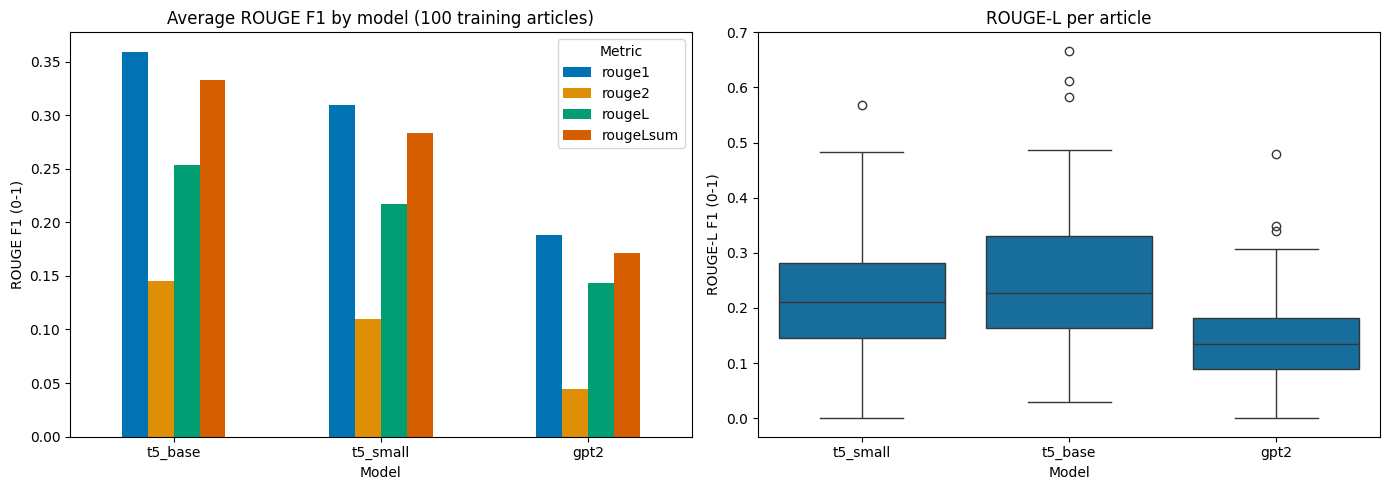

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_palette("colorblind")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

comparison_df.plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Average ROUGE F1 by model (100 training articles)")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("ROUGE F1 (0-1)")
axes[0].legend(title="Metric")

per_row_long = pd.DataFrame(
    {col: per_row_df[f"{col}_rougeL"] for col in PRED_COLS}
).melt(var_name="model", value_name="rougeL")
sns.boxplot(data=per_row_long, x="model", y="rougeL", ax=axes[1])
axes[1].set_title("ROUGE-L per article")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("ROUGE-L F1 (0-1)")

plt.tight_layout()
plt.show()

## Wrap-up

**Which metrics felt most informative? Why?**
ROUGE, because it gives partial credit for overlapping words.
- ROUGE-1 checks shared words, but ignores order (shuffled text still scored 1.0).
- ROUGE-2 checks shared word pairs, so it rewards correct phrasing. It showed the biggest gap between models.
- ROUGE-Lsum suits multi-sentence summaries like these, so it scored higher than ROUGE-L (0.33 vs. 0.25 for t5-base).
- The boxplot was also useful: it showed that t5-small and t5-base overlap a lot, which the averages hide.

**How did model size impact ROUGE and qualitative quality?**
- t5-base (220M) beat t5-small (60M) on every metric and repeated itself less, but the gap was small.
- GPT-2 (124M) is bigger than t5-small but scored much lower. T5 was trained to summarize; GPT-2 only guesses from "TL;DR:".
- GPT-2 sometimes invented facts that are not in the article.
- Note: T5 was pre-trained on CNN/DailyMail and we tested on the train split, so its scores may be inflated.

**Where did accuracy break down as a metric?**
- Accuracy was 0.0 for all summaries, even after ignoring case and punctuation.
- A summary can be correct but use different words, and accuracy still counts it as wrong.
- Accuracy only works when there is one correct answer, like a class label. Summaries have many correct answers.

**How would you extend this to human eval or adversarial probes?**
- Human eval: ask a few people to rate summaries (1-5) for accuracy, coverage and fluency, without showing which model wrote them.
- Fact check: test whether each summary sentence is supported by the article, since ROUGE can't catch invented facts.
- Adversarial probes: change a name or number in the article and check that the summary changes too.
- Also try putting the key fact at the end of a long article, to test the truncation limit.